In [1]:
import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import matplotlib.pyplot as plt

In [5]:
path = "Intel Image Classification"

train = keras.utils.image_dataset_from_directory(
    path,
    image_size=(224,224),
    color_mode="rgb",
    batch_size=32,
    subset="training",
    seed=123,
    validation_split=0.2
)

test = keras.utils.image_dataset_from_directory(
    path,
    image_size=(224,224),
    color_mode="rgb",
    batch_size=32,
    subset="validation",
    seed=123,
    validation_split=0.2
)

classes = train.class_names
print(classes)

Found 12632 files belonging to 6 classes.
Using 10106 files for training.
Found 12632 files belonging to 6 classes.
Using 2526 files for validation.
['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']


In [6]:
base = keras.applications.VGG16(
    include_top=False,
    weights=None,
    input_shape = (224,224,3)
)
base.load_weights("vgg16_weights_tf_dim_ordering_tf_kernels_notop.h5")

base.trainable=False

In [7]:
model = keras.Sequential([
    layers.Input(shape=(224,224,3)),

    layers.Lambda(keras.applications.vgg16.preprocess_input),
    base,
    layers.GlobalAveragePooling2D(),
    layers.Dense(128,activation="relu"),
    layers.Dense(len(classes),activation="softmax")
])

In [8]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

history = model.fit(
    train,
    validation_data=test,
    epochs=2
)

Epoch 1/2
316/316 ━━━━━━━━━━━━━━━━━━━━ 856s 3s/step - accuracy: 0.8812 - loss: 0.3896 - val_accuracy: 0.9026 - val_loss: 0.2876
Epoch 2/2
316/316 ━━━━━━━━━━━━━━━━━━━━ 877s 3s/step - accuracy: 0.9304 - loss: 0.1961 - val_accuracy: 0.9030 - val_loss: 0.2945


In [9]:
loss, accuracy = model.evaluate(test)

print("Loss:", loss)
print("Accuracy:", accuracy*100)

79/79 ━━━━━━━━━━━━━━━━━━━━ 175s 2s/step - accuracy: 0.9030 - loss: 0.2945
Loss: 0.29451873898506165
Accuracy: 90.30086994171143


1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step


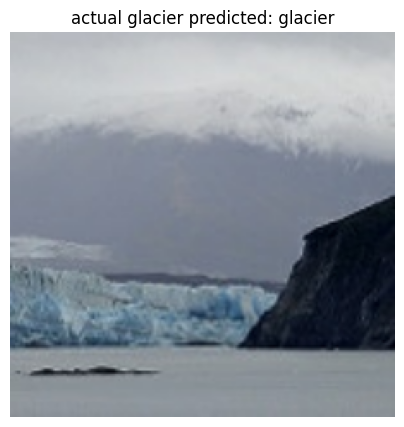

In [19]:
images,labels = next(iter(test))

pred = model.predict(images)
plt.figure(figsize=(12,5))
for i in range(10):
    
    plt.imshow(images[i].numpy().astype("uint8"))
    plt.title(
        f"actual {classes[labels[i]]} predicted: {classes[np.argmax(pred[i])]}"
    )

    plt.axis("off")
plt.show()    

In [21]:
base.trainable = True

for layer in base.layers[:-4]:
    layer.trainable=False

model.compile(
    optimizer=keras.optimizers.Adam(0.00001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)    

model.fit(
    train,
    validation_data=test,
    epochs=2
)

Epoch 1/2
  2/316 ━━━━━━━━━━━━━━━━━━━━ 14:10 3s/step - accuracy: 0.9531 - loss: 0.1150

KeyboardInterrupt: 